# Notebook 01 — Full Data Loading & Data Quality Audit

This notebook is the first stage of the project. It loads the supplied dataset **as-is**, validates the file structure, profiles every column, identifies all data-quality risks, and writes an audit report.

**Non-destructive policy:** the source file is read-only. No rows, characters, encodings, or original columns are overwritten.

## Audit objectives

- Verify encoding, delimiter, header, record count, and field count.
- Detect true missing values and placeholder missing values such as `-`.
- Measure whitespace, Unicode, punctuation, mixed-language, and review-length issues.
- Inspect duplicate rows and duplicate review texts.
- Check rating validity and metadata consistency.
- Produce reproducible CSV/JSON reports for the next preprocessing stage.

In [1]:
from pathlib import Path
import csv, re, json, hashlib, unicodedata, statistics
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path('data/Hotel Arabic-Reviews Dataset.txt')
if not DATA_PATH.exists(): DATA_PATH = Path('/home/ubuntu/work_sentiment/sentiment_analysis_submission/data/Hotel Arabic-Reviews Dataset.txt')
REPORT_DIR = Path('reports'); REPORT_DIR.mkdir(exist_ok=True)
print(DATA_PATH.resolve())

/home/ubuntu/work_sentiment/sentiment_analysis_submission/data/Hotel Arabic-Reviews Dataset.txt


In [2]:
raw = DATA_PATH.read_bytes()
sha256 = hashlib.sha256(raw).hexdigest()
print('bytes:', len(raw)); print('sha256:', sha256)
print('BOM:', raw[:4])
print('decoded preview:', raw[:120].decode('utf-16')[:100])
assert raw[:2] in (b'\xff\xfe', b'\xfe\xff'), 'Expected a UTF-16 BOM.'

bytes: 159337424
sha256: fc3bb8210d4f8a658b77c92fe659e532173432679992d5ae1e6c91969681748b
BOM: b'\xff\xfen\x00'
decoded preview: no	Hotel name	rating	user type	room type	nights	review
1	ف


In [3]:
# Structural audit using the original delimiter and encoding.
field_counts=Counter(); logical_rows=0; malformed=[]
with open(DATA_PATH,encoding='utf-16',newline='') as f:
    reader=csv.reader(f,delimiter='\t'); header=next(reader)
    for line_no,row in enumerate(reader,start=2):
        logical_rows += 1; field_counts[len(row)] += 1
        if len(row)!=len(header): malformed.append({'line':line_no,'fields':len(row)})
print('header:',header); print('logical rows:',logical_rows); print('field counts:',dict(field_counts)); print('malformed:',len(malformed))

header: ['no', 'Hotel name', 'rating', 'user type', 'room type', 'nights', 'review']
logical rows: 409562
field counts: {7: 409562}
malformed: 0


In [4]:
df = pd.read_csv(DATA_PATH, sep='\t', encoding='utf-16', dtype=str, keep_default_na=False)
print(df.shape); display(df.head(3))
print('dtypes:',df.dtypes.to_dict())

(409562, 7)


,no,Hotel name,rating,user type,room type,nights,review
0,1,فندق 72,4,زوج,غرفة قياسية مزدوجة,أقمت ليلة واحدة,“فندق راقي وسوف تتكرر زيارتي له”. الفندق بصراح...
1,2,فندق 72,2,مسافر منفرد,غرفة ديلوكس مزدوجة أو توأم,أقمت ليلة واحدة,“ممتاز”. النظافة والطاقم متعاون.
2,3,فندق 72,5,زوج,غرفة ديلوكس مزدوجة أو توأم,أقمت ليلة واحدة,استثنائي. سهولة إنهاء المعاملة في الاستقبال. ل...


dtypes: {'no': <StringDtype(storage='python', na_value=nan)>, 'Hotel name': <StringDtype(storage='python', na_value=nan)>, 'rating': <StringDtype(storage='python', na_value=nan)>, 'user type': <StringDtype(storage='python', na_value=nan)>, 'room type': <StringDtype(storage='python', na_value=nan)>, 'nights': <StringDtype(storage='python', na_value=nan)>, 'review': <StringDtype(storage='python', na_value=nan)>}


## 1. Missingness and placeholder values

A dash is not a valid user type, room type, or number of nights. It is a placeholder for unknown/missing information. We count it without changing the source.

In [5]:
missing_tokens=['','-','--','N/A','NA','n/a','null','None']
missing_report=[]
for col in df.columns:
    s=df[col].astype(str)
    exact={tok:int((s.str.strip()==tok).sum()) for tok in missing_tokens if (s.str.strip()==tok).any()}
    missing_report.append({'column':col,'empty':int((s.str.strip()=='').sum()),'dash':int((s.str.strip()=='-').sum()),'placeholder_total':sum(exact.values()),'tokens':exact})
missing_df=pd.DataFrame(missing_report); display(missing_df)
missing_df.to_csv(REPORT_DIR/'missingness_report.csv',index=False)

,column,empty,dash,placeholder_total,tokens
0,no,0,0,0,{}
1,Hotel name,0,0,0,{}
2,rating,0,0,0,{}
3,user type,0,50431,50431,{'-': 50431}
4,room type,0,119024,119024,{'-': 119024}
5,nights,0,2517,2517,{'-': 2517}
6,review,0,0,0,{}


## 2. Whitespace, Unicode, and textual noise

These are quality flags, not destructive edits. They show where normalization is needed in Notebook 02.

In [6]:
def whitespace_stats(s):
    s=s.astype(str)
    return {'leading_or_trailing':int((s!=s.str.strip()).sum()),'repeated_spaces':int(s.str.contains(r'\s{2,}',regex=True).sum()),'embedded_newline':int(s.str.contains(r'[\r\n\t]',regex=True).sum())}
text_cols=['Hotel name','user type','room type','nights','review']
ws=pd.DataFrame([{'column':c,**whitespace_stats(df[c])} for c in text_cols]); display(ws); ws.to_csv(REPORT_DIR/'whitespace_report.csv',index=False)
review=df['review'].astype(str)
unicode_counts=Counter(ch for text in review for ch in text if unicodedata.category(ch).startswith('C'))
print('control characters in reviews:',unicode_counts.most_common(20))
print('review length:',review.str.len().describe(percentiles=[.5,.9,.95,.99]).to_dict())

,column,leading_or_trailing,repeated_spaces,embedded_newline
0,Hotel name,0,288,0
1,user type,0,0,0
2,room type,0,3,0
3,nights,0,0,0
4,review,61794,33739,0


control characters in reviews: [('\u200f', 428), ('\u200b', 56), ('\u200e', 40), ('\u202a', 3), ('\ue106', 2), ('\uf8ff', 2), ('\ue416', 2), ('\u200c', 1), ('\U00011e27', 1), ('\u200d', 1), ('\u202c', 1)]
review length: {'count': 409562.0, 'mean': 125.32567962848115, 'std': 121.47874940022095, 'min': 5.0, '50%': 89.0, '90%': 258.0, '95%': 342.0, '99%': 590.0, 'max': 3669.0}


## 3. Duplicates and label quality

In [7]:
ratings=pd.to_numeric(df['rating'],errors='coerce')
print('invalid/missing ratings:',int(ratings.isna().sum()),'outside 1..5:',int((~ratings.isna() & ~ratings.between(1,5)).sum()))
print('duplicate full rows:',int(df.duplicated().sum()))
review_counts=review.value_counts()
print('review-text groups repeated:',int((review_counts>1).sum()))
print('extra duplicate occurrences:',int(review_counts[review_counts>1].sub(1).sum()))
print('rating counts:'); display(df['rating'].value_counts(dropna=False).sort_index().to_frame('count'))

invalid/missing ratings: 0 outside 1..5: 0


duplicate full rows: 0


review-text groups repeated: 2693
extra duplicate occurrences: 9461
rating counts:


,count
rating,
1,14382
2,38467
3,80326
4,132208
5,144179


## 4. Semantic consistency checks

Some values look like room descriptions but occur in `user type`. We flag them for human review rather than silently moving them between columns.

In [8]:
room_keywords=r'غرفة|جناح|استوديو|شقة|سرير|توأم|ديلوكس|قياسية|سوبيريور'
user_suspect=df['user type'].astype(str).str.contains(room_keywords,case=False,regex=True,na=False)
print('user_type values matching room-description patterns:',int(user_suspect.sum()))
print(df.loc[user_suspect,['user type','room type']].value_counts().head(20))
print('unique hotels:',df['Hotel name'].nunique(),'unique users:',df['user type'].nunique(),'unique rooms:',df['room type'].nunique(),'unique nights:',df['nights'].nunique())

user_type values matching room-description patterns: 72
user type                    room type
استوديو كلاسيكي - أسرة توأم  -            69
جناح بغرفتي نوم أسرة توأم    -             3
Name: count, dtype: int64
unique hotels: 1173 unique users: 6 unique rooms: 1187 unique nights: 34


In [9]:
# Language/script and punctuation indicators for the review column.
script_report={
 'arabic_chars': int(review.str.count(r'[\u0600-\u06ff]').sum()),
 'latin_chars': int(review.str.count(r'[A-Za-z]').sum()),
 'digits': int(review.str.count(r'\d').sum()),
 'question_exclamation': int(review.str.count(r'[؟?!]').sum()),
 'urls': int(review.str.contains(r'https?://|www\.',regex=True).sum())
}
print(script_report)

{'arabic_chars': 40706702, 'latin_chars': 255165, 'digits': 144420, 'question_exclamation': 29472, 'urls': 3}


In [10]:
audit_summary={
 'source':str(DATA_PATH.resolve()),'sha256':sha256,'encoding':'UTF-16LE with BOM','delimiter':'TAB',
 'records':int(len(df)),'columns':list(df.columns),'malformed_rows':len(malformed),
 'duplicate_full_rows':int(df.duplicated().sum()),'repeated_review_groups':int((review_counts>1).sum()),
 'extra_duplicate_review_occurrences':int(review_counts[review_counts>1].sub(1).sum()),
 'invalid_or_missing_ratings':int(ratings.isna().sum()),'ratings_outside_1_to_5':int((~ratings.isna() & ~ratings.between(1,5)).sum()),
 'user_type_room_like_values':int(user_suspect.sum()),'missingness':missing_report,'whitespace':ws.to_dict('records'),
 'review_length':{k:float(v) for k,v in review.str.len().describe().to_dict().items()},'script_indicators':script_report}
(REPORT_DIR/'data_quality_audit.json').write_text(json.dumps(audit_summary,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(audit_summary,ensure_ascii=False,indent=2)[:5000])

{
  "source": "/home/ubuntu/work_sentiment/sentiment_analysis_submission/data/Hotel Arabic-Reviews Dataset.txt",
  "sha256": "fc3bb8210d4f8a658b77c92fe659e532173432679992d5ae1e6c91969681748b",
  "encoding": "UTF-16LE with BOM",
  "delimiter": "TAB",
  "records": 409562,
  "columns": [
    "no",
    "Hotel name",
    "rating",
    "user type",
    "room type",
    "nights",
    "review"
  ],
  "malformed_rows": 0,
  "duplicate_full_rows": 0,
  "repeated_review_groups": 2693,
  "extra_duplicate_review_occurrences": 9461,
  "invalid_or_missing_ratings": 0,
  "ratings_outside_1_to_5": 0,
  "user_type_room_like_values": 72,
  "missingness": [
    {
      "column": "no",
      "empty": 0,
      "dash": 0,
      "placeholder_total": 0,
      "tokens": {}
    },
    {
      "column": "Hotel name",
      "empty": 0,
      "dash": 0,
      "placeholder_total": 0,
      "tokens": {}
    },
    {
      "column": "rating",
      "empty": 0,
      "dash": 0,
      "placeholder_total": 0,
      "toke

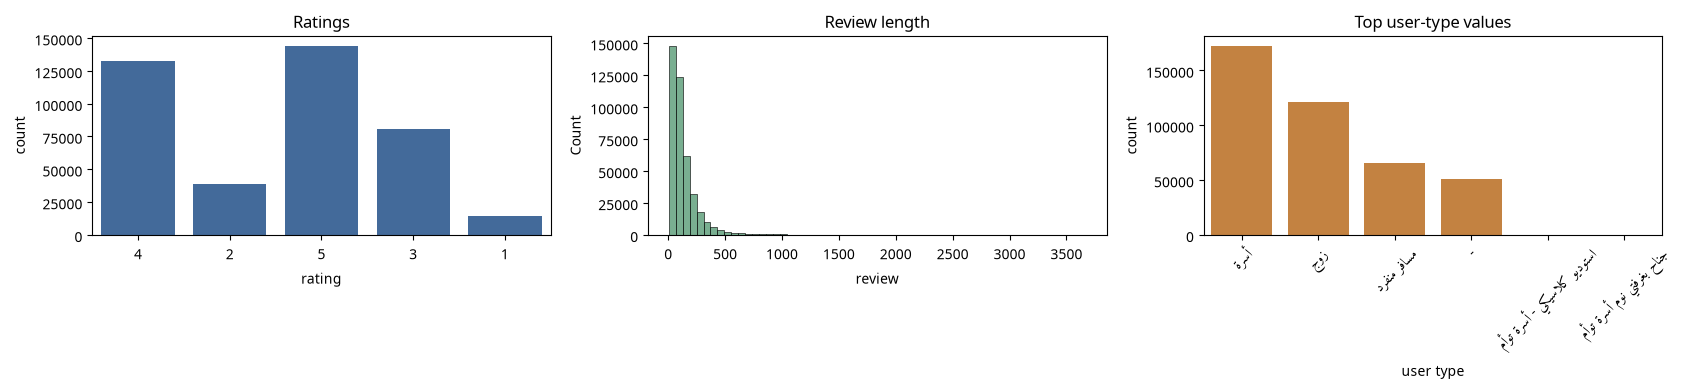

In [11]:
fig,ax=plt.subplots(1,3,figsize=(17,4))
sns.countplot(data=df,x='rating',ax=ax[0],color='#3568a8'); ax[0].set_title('Ratings')
sns.histplot(review.str.len(),bins=60,ax=ax[1],color='#4c956c'); ax[1].set_title('Review length')
sns.countplot(data=df,x='user type',order=df['user type'].value_counts().head(8).index,ax=ax[2],color='#d9822b'); ax[2].tick_params(axis='x',rotation=45); ax[2].set_title('Top user-type values')
plt.tight_layout(); plt.savefig(REPORT_DIR/'data_quality_overview.png',dpi=150); plt.show()

## Audit conclusion

The source is structurally readable and has no malformed logical rows, but it requires a documented derived-data layer for encoding-aware loading, placeholder missingness, whitespace normalization, Arabic normalization, numeric extraction from `nights`, and quality flags. Notebook 02 performs those transformations without overwriting the source.